# The `sklearn` Module

## General ML Workflow

The scikit-learn library (which uses `sklearn` as the module name in Python) provides ready-made algorithms and functions for ML. Using `sklearn` makes ML much easier by providing standard workflows.

Machine learning follows a standard sequence of steps. These are the basic steps and how they are facilitated by `sklearn`:

|Step|Description|Relevant `sklearn` Code|
|:-|:-|:-|
|1. Gather Data|Collect a dataset (either labelled or unlabelled).|`numpy.loadtext()`|
|2. Prepare Data|Clean data, fix missing values, scale features, etc.|`MinMaxScaler(), StandardScaler()`**NOT IN SYLLABUS**|
|3. Choose a Model|Pick an algorithm to train the model (e.g., kNN or k-Means).|Construct an **estimator object** (e.g., `KNeighborsClassifier()`, `KMeans()`)|
|4. Train Model|Feed training data to the model.|Use `test_train_split()` to form training and test data<br>Call `<estimator>.fit()` with training data|
|5. Evaluate Model|Test model (e.g., on unseen data).|Call `<estimator>.score()` with test data or `cross_validate()` with multiple folds of training and test data to quantify performance|
|6. Tune Parameters|Adjust hyperparameters to improve performance.|Use `<estimator>.get_params()`,`<estimator>.set_params()`, `GridSearchCV()`|
|7. Make Predictions|Use the trained model to make predictions.|Call `<estimator>.predict()`|


## Contents
- [sklearn for  knn](##k-Nearest-Neighbours-with-sklearn)
- [sklearn for k-means](##k-Means-with-sklearn)

---

## k-Nearest Neighbours with sklearn

### Steps 1 and 2 (Gather Data, Prepare Data)

Let us use sklearn to perform k-Nearest Neighbours classification using `labelled.csv`, which would have been obtained by following steps 1 and 2 of the general steps required for ML. Recall that each line represents a song with two features (song length, song tempo) and its corresponding genre.

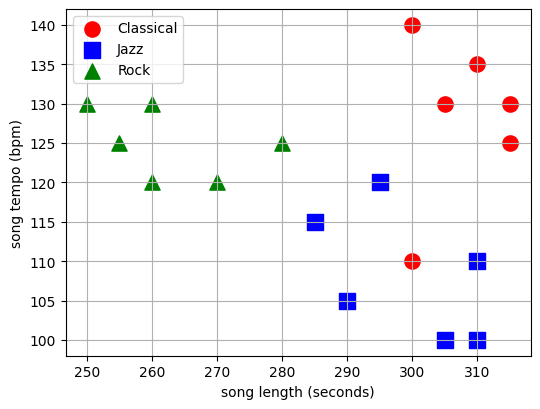

In [1]:
from ml_lib import plot_labelled_data
import numpy as np
## using numpy to extract features and label

features = np.loadtxt('labelled.csv', float, delimiter=',', usecols=(0, 1))
labels = np.loadtxt('labelled.csv', str, delimiter=',', usecols=(2,))
plot_labelled_data(features, labels, y_units="bpm", x_units="seconds")


### Step 3 (Choose a Model)

For step 3, we need to create a `KNeighborsClassifier` estimator. The `KNeighborsClassifier` class is in the `sklearn.neighbors` module and accepts an `n_neighbors` parameter to set the value of k. In this case, we use k = 3 :

In [2]:
from sklearn.neighbors import KNeighborsClassifier
estimator = KNeighborsClassifier(n_neighbors=3) # default n_neighbors=5

### Step 4 (Train Model)

The dataset needs to be partitioned into 
- data used for training the model
- data used for testing/validating the model

For step 4, we can split the labelled data into training data and test data, then use the training data to train the model. To perform the split, we use the `train_test_split()` helper function in the `sklearn.model_selection` module. The function accepts 2 lists/arrays for the features and labels, then returns a tuple of 4 lists/arrays for the features and labels of the training and test data. The function also accepts parameters to control the splitting, some of which are highlighted below:

|Function|`train_test_split()`|
|:-|:-|
|Inputs|Required:<br>- list/array of features<br>- list/array of labels<br>Optional:<br>- `test_size`: if float, proportion of dataset to include in test split; if int, absolute number of test samples; default 0.25<br>- `shuffle`: whether or not to shuffle the data before splitting; default `True`|
|Outputs|Tuple of:<br>- list/array of training split features<br>- list/array of test split features<br>- list/array of training split labels<br>- list/array of test split labels|

The following code loads the full labelled data from `labelled.csv`, then uses `train_test_split()` to perform an 80%-20% split into training and test data:

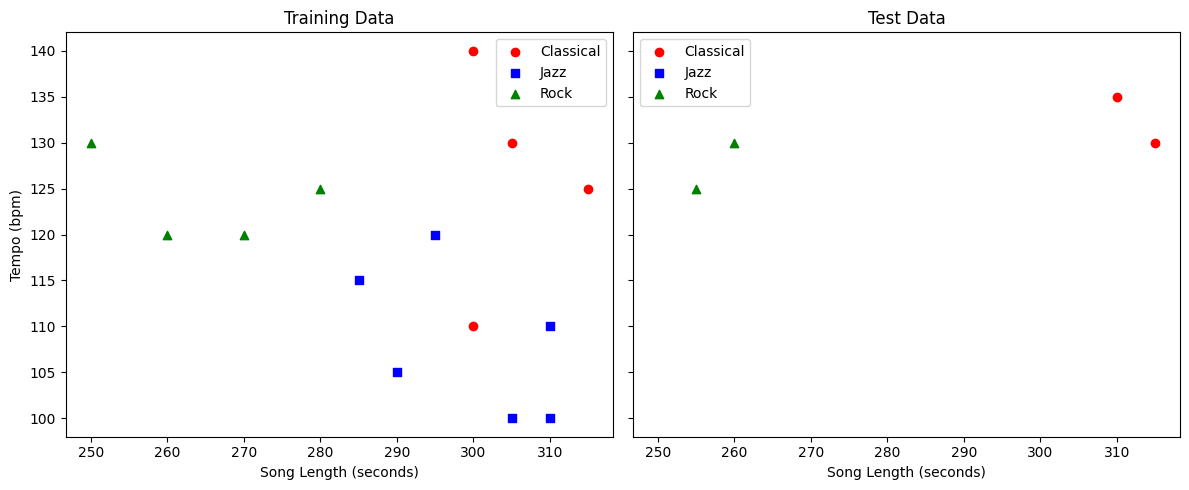

In [3]:
from sklearn.model_selection import train_test_split
from ml_lib import plot_train_test

# default Non-deterministic
train_features, test_features, train_labels, test_labels = \
    train_test_split(features, labels, test_size=0.2)


# # Deterministic
# train_features, test_features, train_labels, test_labels = \
#     train_test_split(features, labels, test_size=0.2, shuffle=False)

plot_train_test(train_features, test_features, train_labels, test_labels, labels)


<div class="alert">
Default behaviour of `train_test_split()`

- Non-deterministics
- there is no guaranteed that the training/test set have same proportions of the different labeled(classes) data 
- Notice that some classes may be missing
</div>

In [ ]:
## Train the model
estimator.fit(train_features, train_labels) #fit() returns self


<div class="alert">

For kNN, `fit()` simply stores the training data in full as kNN needs the complete dataset to determine the nearest neighbours during prediction, but for other models such as neural networks, `fit()` trains the model by learning weights/parameters from the data.

</div>

After calling `fit()`, we can subsequently look up the training data's size, number of features and set of possible labels using the estimator's `n_samples_fit_`, `n_features_in_` and `classes_` attributes:

In [ ]:
print(estimator.n_samples_fit_, estimator.n_features_in_)
print(estimator.classes_)

### Step 5 (Evaluate Model)

For step 5, we can evaluate the model using the test data by calling the estimator's `score()` method using the test data's features and labels. For kNN, the score is just the model's accuracy or proportion of correctly predicted labels for the test data:

In [ ]:
print(estimator.score(test_features, test_labels))

## <span style="color:red"> K-fold Cross-validation</span>
As previously discussed, evaluating a model on a single train/test split may not be reliable, since the result depends on how the data happened to be divided. For a more robust estimate, we can use k-fold cross-validation, which averages performance across multiple splits.

The dataset is divided into k folds (partitions) of roughly equal size (e.g., k = 5, as shown below). In each of the k iterations, one fold is used for testing and the remaining folds for training, so that every data point is used for testing exactly once and for training in the other iterations.

The k resulting accuracy scores are then averaged to give a single, more reliable measure of the model's performance — one that is less dependent on any single choice of split.


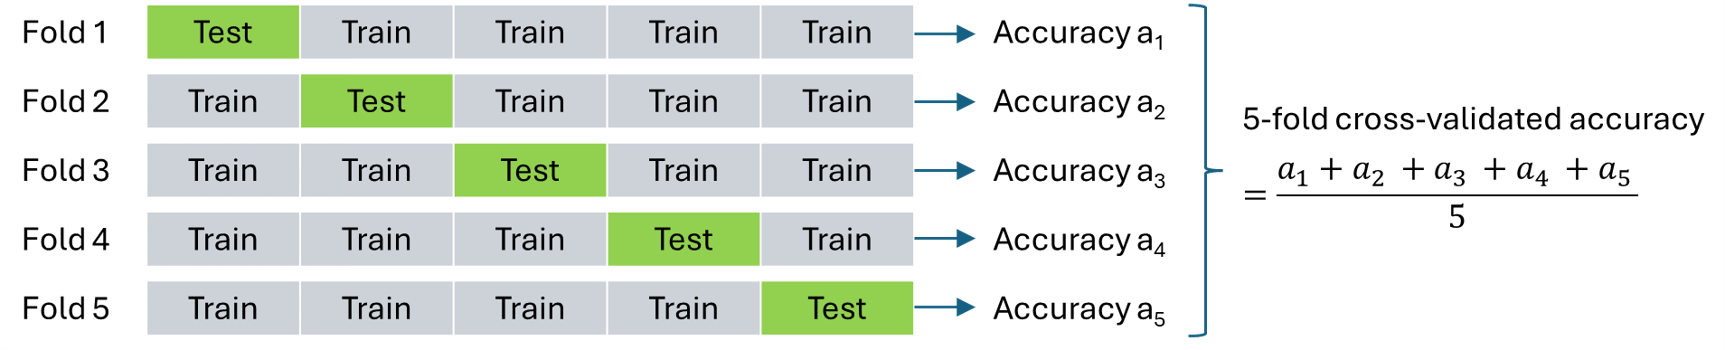

---
#### Show the k-folds that are used internally by `cross_validate()`



In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_validate, StratifiedKFold
import numpy as np
k_fold = 4
splitter = StratifiedKFold(n_splits=k_fold)
## split will return ( [training indices], [testing indices]), different from the python make_fold earlier
for  f, fold in enumerate(splitter.split(features, labels),1): # iterate for each fold
    train_indices, test_indices = fold
    print(f"fold {f}")
    plot_train_test( features[ train_indices], features[test_indices], 
                     labels [ train_indices], labels[test_indices], labels)
    


### `cross_validate`

To do this, we can use the `cross_validate()` helper function in the `sklearn.model_selection` module. The function accepts an estimator object, 2 lists/arrays for the features and labels, and an optional cv parameter for the number of folds. It then returns a **dictionary** that contains a list of test scores for each split. 

In addition, `cross_validate()` ensures that the proportion of each class label in the original dataset is preserved in every fold, rather than folds being formed purely by random partitioning. This matters especially when classes are imbalanced — without stratification, a fold could end up with very few (or even none) of the minority class examples, leading to unreliable accuracy scores for that fold.

|Function|`cross_validate()`|
|:-|:-|
|Inputs|Required:<br>- list/array of features<br>- estimator object<br>- list/array of features<br>- list/array of labels<br>Optional:<br>`cv`: number of folds; default 5|
|Outputs|Dictionary with list of test scores under key `'test_score'`|

The following code uses `cross_validate()` and `np.mean()` to calculate the 4-fold cross-validated accuracy for our kNN estimator (with initial k = 3):

In [ ]:
from sklearn.model_selection import cross_validate
cv_output = cross_validate(estimator, features, labels, cv=4)
import numpy as np
print(np.mean(cv_output['test_score']))

In [ ]:
## Other keys in the dict
for key in cv_output:
    print( f"{key}:{cv_output[key]}")

<div class="alert">

The dictionary returned by `cross_validate()` contains additional outputs besides the test scores. If only the test scores are needed, you may wish to use **`cross_val_score()`** instead of cross_validate() so an array is returned instead of a dictionary. This simplifies the code slightly:
</div>   

In [ ]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(estimator, features, labels, cv=4)
import numpy as np
print(np.mean(scores))

### Step 6 (Tune Parameters)

For step 6, we can now adjust the hyperparameter k to maximise the model's score. To manipulate k, we can use the estimator's `get_params()` and `set_params()` methods. The `get_params()` method returns a dictionary of parameter names and their values, such as the `n_neighbors` parameter for kNN that corresponds to k:

In [ ]:
print(estimator.get_params())

From the output of `get_params()`, we see that the value of k is currently 3.

Suppose we now want to increase k from 3 to 5. To do this, we use `set_params()` and provide the new `n_neighbors` parameter using keyword arguments:

In [ ]:
estimator.set_params(n_neighbors=5)

We can verify that the `n_neighbors` parameter is indeed updated:

In [ ]:
print(estimator.get_params()['n_neighbors'])

Using `set_params()`, we can proceed to vary k and choose the value for k that gives the highest 4-fold cross-validated accuracy:

In [ ]:
from sklearn.model_selection import cross_val_score

cv = 4
# Maximum k is size of (cv – 1) folds.
max_k = int((cv - 1) / cv * len(features))
k_values = range(1,max_k+1)
scores = []
for k in k_values:
    estimator.set_params(n_neighbors=k)
    score = np.mean(
        cross_val_score(estimator, features, 
        labels, cv=cv)) # cross_validate will create the folds once (deterministric) using StratifiedFold(shuffle=False) 
    scores.append(score)
highest_score = max(scores)
highest_score_index = scores.index(highest_score)
best_k = k_values[highest_score_index]
estimator.set_params(n_neighbors=best_k)

print(f"Best k is {best_k} ({highest_score})")


In this case, the highest 4-fold cross-validated accuracy is obtained when k = 5.

---
### Using built-in evaluation (NOT IN Syllabus)


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, KFold, RepeatedStratifiedKFold, GridSearchCV

cv = 4
max_k = int((cv - 1) / cv * len(features))
k_values = range(1,max_k+1)
#splitter = KFold(n_splits=cv,shuffle=True)
splitter = StratifiedKFold(n_splits=cv,shuffle=True)
# splitter = RepeatedStratifiedKFold(
#     n_splits=cv, 
#     n_repeats=10, 
#     random_state=42)

param_grid = {'n_neighbors':k_values}
grid = GridSearchCV(
    KNeighborsClassifier(),
    param_grid,
    cv = splitter # Default uses StratifiedKFold(n_splits=cv, shuffle=False)
)
grid.fit(features, labels)
best_k = grid.best_params_["n_neighbors"]
best_score = grid.best_score_
estimator.set_params(n_neighbors=best_k)
print(best_k)
print(best_score)

---

### Step 7 (Make Predictions)

For step 7, we can proceed to use the trained model with tuned parameters to make predictions using the `predict()` and `predict_proba()` methods. Both methods accept a list/array of unlabelled data points. The `predict()` method returns a corresponding array of predicted labels while the `predict_proba()` method returns an 2-dimensional array of probabilities with each row corresponding to a data point and each column corresponding to a label based on the `classes_` attribute.

Our estimator has already been set to use the tuned parameter k = 5. However, it may still be using the split training data from the last call to `train_test_split()`, so we first call `fit()` again with the full dataset:

In [ ]:
estimator.fit(features, labels)

We can then use `predict()` to predict the genre for a new song with length 280s and tempo 115bpm. Note that a list of lists is used as `predict()` expects to be given a list/array of data points, not just a single data point:

In [ ]:
print(estimator.get_params())
print(estimator.predict([[280.0, 115.0]]))

This tells us that the predicted genre of the new song is Jazz for k = 5.

We can also call `predict_proba()` to estimate the probabilities for each label:

In [ ]:
print(estimator.classes_)
print(estimator.n_neighbors)
print(estimator.predict_proba([[280.0, 115.0]]))

This tells us that the model predicts probabilities of 0.0 for Classical, 0.6 for Jazz, and 0.4 for Rock. These probabilities align with the distribution of the 5 nearest neighbours when visualised graphically:

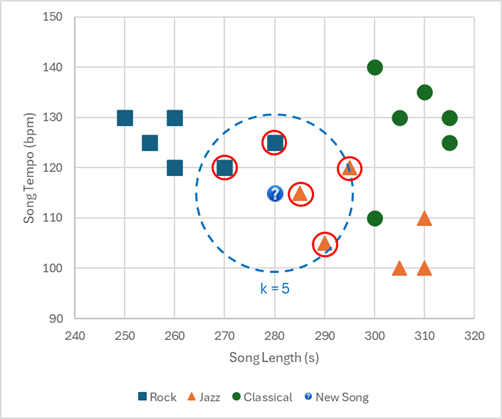

We can verify this by calling the `kneighbors()` method, which accepts a list/array of unlabelled data points and returns a tuple of two arrays, one containing the lengths to the k nearest neighbours and another containing indices of the k nearest neighbours in the training data. The array of indices can subsequently be used with fancy indexing to look up the corresponding labels:

In [ ]:
distances, indices = estimator.kneighbors([[280.0, 115.0]])
print(distances)
print(indices)
print(np.array(labels)[indices])

<div class="alert">

### Additional Note
    
Use `cross_validate()` under Step 5 of kNN a few times with the default options. Examine the output and state if it is deterministic. (Changing this behaviour is not in the syllabus)


</div>

---
## ADDITIONAL Tuning Workflow options

In [ ]:
## To make cross_validate non-deterministic, create a StratifiedKFold object with shufflle=True

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_validate, StratifiedKFold
import numpy as np

k_fold = 4
cv = StratifiedKFold(n_splits=k_fold, shuffle=True) # non-deterministric

estimator = KNeighborsClassifier(n_neighbors=3)
cv_output = cross_validate(estimator, features, labels, cv=cv)
print(np.mean(cv_output['test_score']))


In [ ]:
## Tuning k values with repeatitions

from sklearn.model_selection import cross_val_score, KFold
import numpy as np

k_fold = 4
max_k = int( ((k_fold-1)/k_fold)* len(features))
k_values = range(1, max_k + 1)
cv = RepeatedStratifiedKFold(
    n_splits=k_fold, 
    n_repeats=10, 
    random_state=49)
best_k=[]
for k in k_values:
    estimator.set_params(n_neighbors=k)
    scores = cross_val_score(estimator, features, labels, cv=cv)
    print(k, np.mean(scores))
    best_k.append( np.mean(scores))

print(f"Best k is {k_values[best_k.index(max(best_k))]} ({max(best_k)})")



----

## K-Means with sklearn

### Steps 1 and 2 (Gather Data, Prepare Data)

Next, let us use `sklearn` to perform k-Means clustering using `unlabelled.csv`, which would have been obtained by following steps 1 and 2 of the general steps required for ML. (Note that `unlabelled.csv` is just `labelled.csv` without the labels.)


In [ ]:

from knn_lib import plot_data
import numpy as np
## using numpy to extract features and label

features = np.loadtxt('labelled.csv', float, delimiter=',', usecols=(0, 1))

plot_data(features )


### Step 3 (Choose a Model)

For step 3, we need to create a `KMeans` estimator. The `KMeans` class is in the `sklearn.cluster` module and accepts `n_clusters`, `n_init` and `max_iter` as parameters. The `n_clusters` parameter sets the value of k (i.e., number of clusters), the `n_init` parameter sets the number of times the algorithm is run with different initial centroids, and the `max_iter` parameter sets the maximum number of iterations per run of the algorithm. In this case, we use k = 3, run the algorithm just once and limit the number of iterations to 10:

In [ ]:
from sklearn.cluster import KMeans
estimator = KMeans(n_clusters=3, n_init=1, max_iter=10)

### Step 4 (Train Model)

For step 4, we call the estimator’s `fit()` method using the unlabelled data:

In [ ]:
estimator.fit(features)

After calling `fit()`, we can subsequently use the `cluster_centers_`, `labels_`, `n_iter_` and `n_features_in_` attributes to get the centroid coordinates, the labels of each point, the number of iterations run and the number of features respectively:

In [ ]:
print(f"centroids:{estimator.cluster_centers_}")
print(f"labels:{estimator.labels_}")
print(f"iterations run:{estimator.n_iter_}")
print(f"num of features:{estimator.n_features_in_}")

Note that the labels 0, 1 and 2 simply correspond to the indices of the centroids in `cluster_centers_`.

### Step 5 (Evaluate Model)

For step 5, we can evaluate the quality of the clustering by measuring the inertia (i.e., the sum of squared distances from each point to the nearest centroid). Lower inertia values indicate better clustering as data points are closer to their centroids. We get the inertia by either inspecting the estimator’s `inertia_` attribute or by calling the estimator’s `score()` method using the unlabelled data:

In [ ]:
print(estimator.inertia_)
print(estimator.score(features))

Note how `score()` is just the negative of the inertia. This is to ensure consistency with other sklearn models so higher scores always indicate higher quality.

### Step 6 (Tune Parameters)

For step 6, we can adjust the `n_init` parameter so k-Means is run multiple times with different random initial centroids. To manipulate `n_init`, we can use the standard `get_params()` and `set_params()` methods:

In [ ]:
estimator.set_params(n_init=10)
print(estimator.get_params()['n_init'])

We can then run `fit()` again to repeat the k-Means algorithm `n_init` times and keep the best clustering based on the lowest inertia.

In [ ]:
estimator.fit(features)

### Step 7 (Make Predictions)

For step 7, we can predict the closest cluster of a new data point using the `predict()` method, which accepts a list/array of unlabelled data points and returns a corresponding array of cluster indices. The prediction is done by choosing the cluster with the nearest centroid to each data point.

Let us try to predict the cluster for a new song with length 280s and tempo 115bpm:

In [ ]:
print(estimator.predict([[280.0, 115.0]]))

This corresponds to a cluster in the list of centroids:

In [ ]:
print(estimator.cluster_centers_)

For k-Means, the converged cluster assignment of the training data is also a form of prediction. We can access these assignments by calling `predict()` using the original data or by examining the `labels_` attribute after clustering:

In [ ]:
print(estimator.predict(features))
print(estimator.labels_)

Since running k-Means on some data and getting the final cluster assignment is a common operation, we can use `fit_predict()` to combine the fitting and prediction steps into a single method: 

In [ ]:
print(estimator.fit_predict(features))

In [ ]:
## Plot the data with their predicted labels
from knn_lib import plot_labelled_data
plot_labelled_data(features, estimator.labels_, y_units="bpm", x_units="seconds")


<div class="alert">

### Exercise : The Classic Iris Dataset

Three species of the iris plant are iris setosa, iris versicolor and iris virginica. 50 samples of each species are collected, then the length and width of their flower petals are measured. This data is stored in a file named `iris_train.csv`. Each line has petal length, petal width and species name separated by commas. 

a)	Use `sklearn` and 5-fold cross-validation to output the optimal value of k in kNN for the data in `iris_train.csv`, then calculate the accuracy with the following test data:
    
|Petal Length|Petal Width|Species|
|-|-|-|
|1.5|0.2|Setosa|
|1.2|0.2|Setosa|
|4.3|1.3|Versicolor|
|4.1|1.3|Versicolor|
|5.6|2.1|Virginica|

</div>

## Solution

In [ ]:
## Code


<div class="alert">

b)	Discard the labels. Use `sklearn` to output the clustering of data in `iris_train.csv` (without the labels) into 3 groups with the lowest inertia out of 100 initial conditions.

</div>

In [ ]:
## Code